# 💳 Credit card fraud detection

Goal: predict the probability that a single card transaction is fraudulent.
See the README for the business context.

Contents:

1. Data loading and cleaning
2. Exploratory data analysis (EDA)
3. Feature importance analysis
4. Model training and tuning - logistic regression, random forest, XGBoost
5. Model selection with cross-validation
6. Decision threshold and final evaluation on the test set

Shared loading / splitting / feature code lives in `common.py`, so this
notebook, `train.py` and `predict.py` all prepare data the same way.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import xgboost as xgb
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    confusion_matrix,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from common import FEATURES, SEED, TARGET, add_features, clean_data, load_data, split_data

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 40)

## 1. Data loading and cleaning

The dataset is committed as `dataset/creditcard.csv.gz`
(source: [OpenML 1597](https://www.openml.org/d/1597), ULB).

In [2]:
df_raw = load_data()
print(df_raw.shape)
df_raw.head()

(284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,-0.551600,-0.617801,-0.991390,-0.311169,1.468177,-0.470401,0.207971,0.025791,0.403993,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,1.612727,1.065235,0.489095,-0.143772,0.635558,0.463917,-0.114805,-0.183361,-0.145783,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,0.624501,0.066084,0.717293,-0.165946,2.345865,-2.890083,1.109969,-0.121359,-2.261857,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,-0.226487,0.178228,0.507757,-0.287924,-0.631418,-1.059647,-0.684093,1.965775,-1.232622,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,-0.822843,0.538196,1.345852,-1.119670,0.175121,-0.451449,-0.237033,-0.038195,0.803487,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [3]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

All 31 columns are numeric. Checking missing values and duplicates:

In [4]:
print("Missing values:", df_raw.isna().sum().sum())
print("Duplicate rows:", df_raw.duplicated().sum())
print("Duplicate fraud rows:", df_raw[df_raw.duplicated()][TARGET].sum())

Missing values: 0


Duplicate rows: 1081


Duplicate fraud rows: 19


There are no missing values, but there are duplicate rows. Exact duplicates are
dropped **before** splitting. Otherwise a transaction could appear in both the
training and the test set, which would inflate the test score.

In [5]:
df = clean_data(df_raw)
print(df.shape)
print(f"Fraud: {df[TARGET].sum()} of {len(df)} ({df[TARGET].mean():.3%})")

(283726, 31)
Fraud: 473 of 283726 (0.167%)


Value ranges:

In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Time,283726.0,94811.077600,47481.047891,0.000000,54204.750000,84692.500000,139298.000000,172792.000000
V1,283726.0,0.005917,1.948026,-56.407510,-0.915951,0.020384,1.316068,2.454930
V2,283726.0,-0.004135,1.646703,-72.715728,-0.600321,0.063949,0.800283,22.057729
V3,283726.0,0.001613,1.508682,-48.325589,-0.889682,0.179963,1.026960,9.382558
V4,283726.0,-0.002966,1.414184,-5.683171,-0.850134,-0.022248,0.739647,16.875344
V5,283726.0,0.001828,1.377008,-113.743307,-0.689830,-0.053468,0.612218,34.801666
V6,283726.0,-0.001139,1.331931,-26.160506,-0.769031,-0.275168,0.396792,73.301626
V7,283726.0,0.001801,1.227664,-43.557242,-0.552509,0.040859,0.570474,120.589494
V8,283726.0,-0.000854,1.179054,-73.216718,-0.208828,0.021898,0.325704,20.007208
V9,283726.0,-0.001596,1.095492,-13.434066,-0.644221,-0.052596,0.595977,15.594995


Observations:

- `V1`..`V28` are PCA components: centred on 0, already scaled, but with long
  tails (min/max far beyond the quartiles).
- `Time` covers 0 - 172,792 s, i.e. two days.
- `Amount` ranges from 0 to ~25,700 EUR with a median of ~22 EUR, so it is very
  right-skewed.

## 2. Exploratory data analysis

### 2.1 Target variable

,count,share
Class,,
0,283253,0.998333
1,473,0.001667


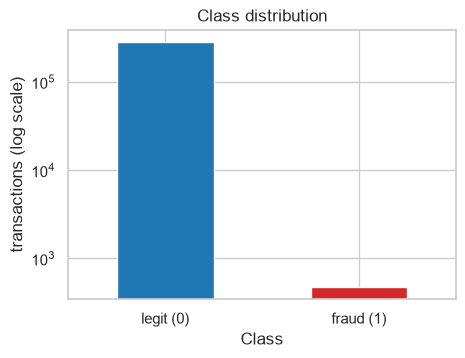

In [7]:
counts = df[TARGET].value_counts()
display(counts.to_frame("count").assign(share=lambda d: d["count"] / d["count"].sum()))

ax = counts.plot.bar(color=["tab:blue", "tab:red"], figsize=(5, 3.5))
ax.set_yscale("log")
ax.set_xticklabels(["legit (0)", "fraud (1)"], rotation=0)
ax.set_ylabel("transactions (log scale)")
ax.set_title("Class distribution")
plt.show()

Fraud is only **~0.17%** of the transactions, so the classes are very imbalanced:

- Accuracy is useless. Predicting "legit" for everything is 99.83% accurate.
- ROC AUC can look great even when the model's fraud alerts are mostly wrong,
  because the huge number of true negatives dominates the false-positive rate.
- The main metric is therefore **PR-AUC (average precision)**, which only looks
  at how well the fraud cases are found and how clean the alerts are. ROC AUC
  is reported alongside.

### 2.2 Transaction amount

          count        mean         std  min   25%    50%     75%       max
Class                                                                      
0      283253.0   88.413575  250.379023  0.0  5.67  22.00   77.46  25691.16
1         473.0  123.871860  260.211041  0.0  1.00   9.82  105.89   2125.87


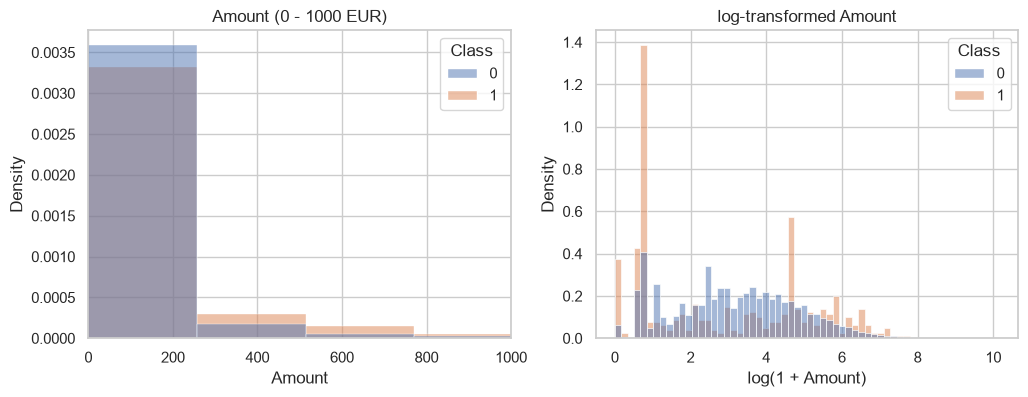

In [8]:
print(df.groupby(TARGET)["Amount"].describe())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=df, x="Amount", hue=TARGET, bins=100, stat="density",
             common_norm=False, ax=axes[0])
axes[0].set_xlim(0, 1000)
axes[0].set_title("Amount (0 - 1000 EUR)")
sns.histplot(x=np.log1p(df["Amount"]), hue=df[TARGET], bins=60, stat="density",
             common_norm=False, ax=axes[1])
axes[1].set_xlabel("log(1 + Amount)")
axes[1].set_title("log-transformed Amount")
plt.show()

- Fraudulent transactions are not generally larger. Their median is lower than
  for legit ones, but their mean is higher (a few large frauds), and many fraud
  amounts are tiny (e.g. 1 EUR - typical "card testing").
- The raw amount is extremely skewed. `log(1 + Amount)` gives a far more usable
  distribution, so the model uses `log_amount` instead of `Amount`.

### 2.3 Time

`Time` is seconds since the first transaction in the dataset. That is
meaningless for a new transaction, so it cannot be used as-is. The time of day
can be, though: `hour = (Time mod 86400) / 3600`.

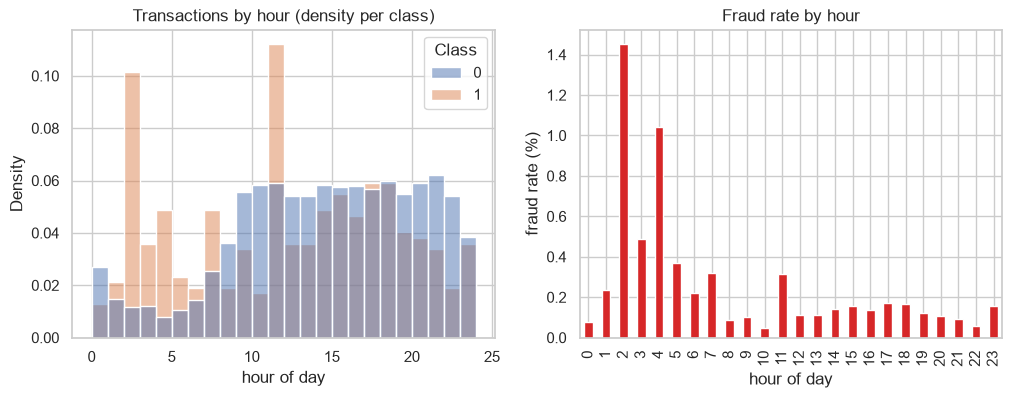

In [9]:
hour = (df["Time"] % 86_400) / 3_600

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(x=hour, hue=df[TARGET], bins=24, stat="density", common_norm=False, ax=axes[0])
axes[0].set_xlabel("hour of day")
axes[0].set_title("Transactions by hour (density per class)")

fraud_rate = df.groupby(hour.astype(int))[TARGET].mean() * 100
fraud_rate.plot.bar(ax=axes[1], color="tab:red")
axes[1].set_xlabel("hour of day")
axes[1].set_ylabel("fraud rate (%)")
axes[1].set_title("Fraud rate by hour")
plt.show()

Legitimate traffic drops sharply at night (hours ~1-7), but fraud does not, so
the **fraud rate is several times higher at night**. `hour` is kept as a feature.

Caveat: the data covers only two days, so this pattern rests on two nights.

### 2.4 PCA features `V1`..`V28`

The features are anonymized, so they can't be interpreted in business terms.
We can still check how differently they are distributed for fraud and legit
transactions.

In [10]:
v_cols = [f"V{i}" for i in range(1, 29)]
means = df.groupby(TARGET)[v_cols].mean().T
means.columns = ["legit mean", "fraud mean"]
means["difference"] = means["fraud mean"] - means["legit mean"]
means.sort_values("difference", key=abs, ascending=False).head(10)

,legit mean,fraud mean,difference
V14,0.011668,-6.835946,-6.847614
V3,0.012853,-6.729599,-6.742452
V17,0.010963,-6.463285,-6.474249
V12,0.009476,-6.103254,-6.112730
V10,0.007663,-5.453274,-5.460937
V7,0.010447,-5.175912,-5.186359
V1,0.013439,-4.498280,-4.511719
V4,-0.010440,4.472591,4.483031
V16,0.007845,-4.000956,-4.008801
V11,-0.006004,3.716347,3.722350


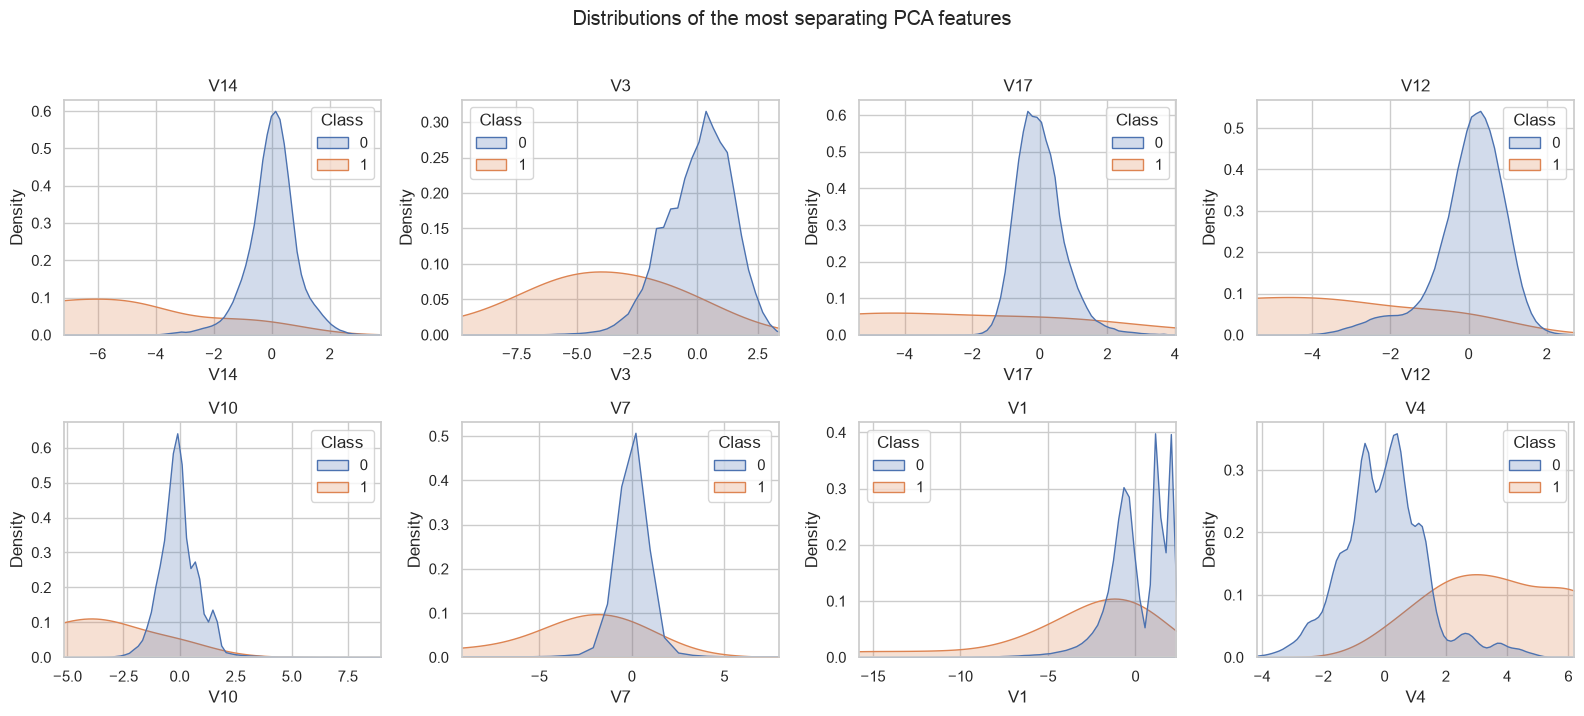

In [11]:
top = means["difference"].abs().sort_values(ascending=False).index[:8]
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for col, ax in zip(top, axes.ravel()):
    sns.kdeplot(data=df, x=col, hue=TARGET, common_norm=False, fill=True, ax=ax,
                warn_singular=False)
    ax.set_title(col)
    ax.set_xlim(df[col].quantile(0.001), df[col].quantile(0.999))
plt.suptitle("Distributions of the most separating PCA features", y=1.02)
plt.tight_layout()
plt.show()

Several components (`V14`, `V3`, `V17`, `V12`, `V10`, `V7`, ...) have clearly
different distributions for fraud. Fraud is shifted to strongly negative (or,
for `V4`/`V11`, positive) values. That is very promising for classification.

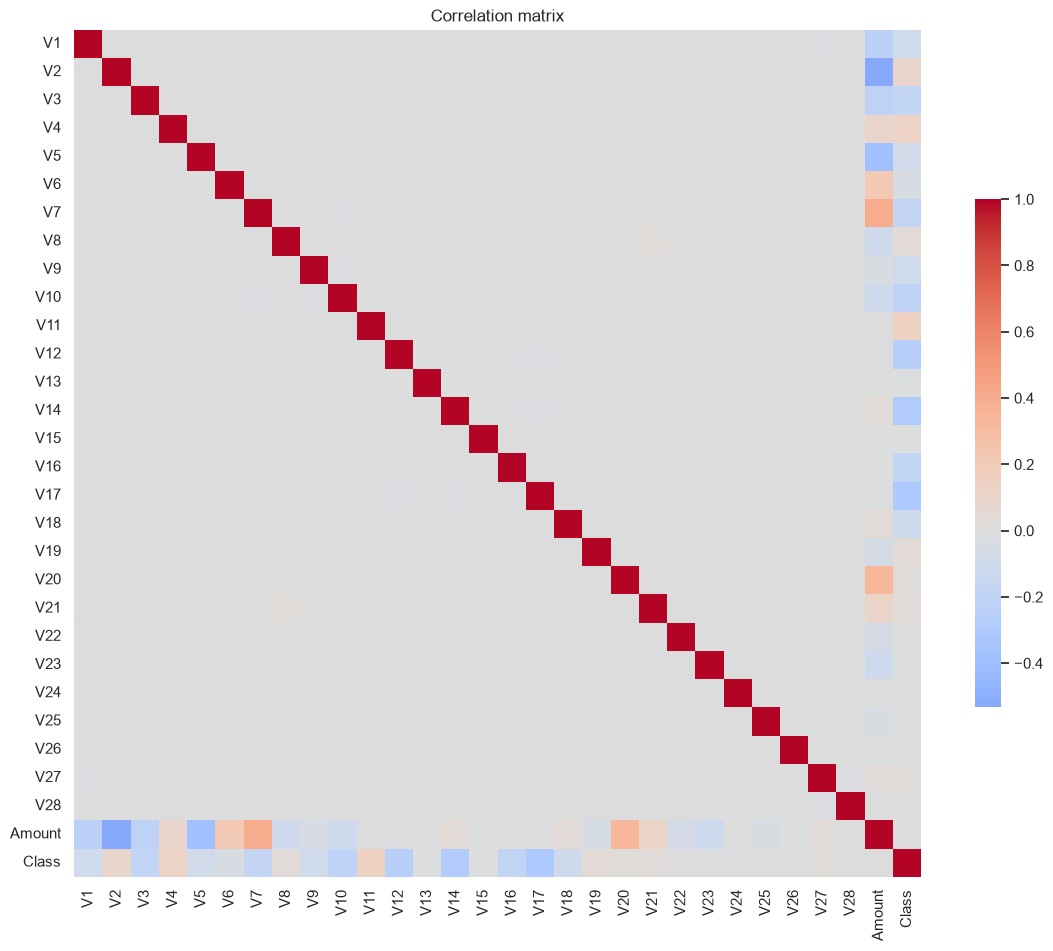

In [12]:
corr = df[v_cols + ["Amount", TARGET]].corr()
plt.figure(figsize=(14, 11))
sns.heatmap(corr, cmap="coolwarm", center=0, square=True, cbar_kws={"shrink": 0.6})
plt.title("Correlation matrix")
plt.show()

The PCA components are uncorrelated with each other (the off-diagonal is ~0, as
PCA guarantees), so there is no multicollinearity to deal with. Some components
correlate with `Amount`, and several correlate with the target.

## 3. Feature importance analysis

First the data is split into train / validation / test (60/20/20, stratified so
every part keeps the 0.17% fraud rate). Feature importance is computed on the
**training set only**, so the test set stays untouched until the end.

In [13]:
df_train, df_val, df_test = split_data(df)
for name, part in [("train", df_train), ("val", df_val), ("test", df_test)]:
    print(f"{name:5s} {len(part):7d} rows, {part[TARGET].sum():3d} fraud ({part[TARGET].mean():.3%})")

X_train, y_train = add_features(df_train), df_train[TARGET].values
X_val, y_val = add_features(df_val), df_val[TARGET].values
X_test, y_test = add_features(df_test), df_test[TARGET].values
print("Features:", FEATURES)

train  170235 rows, 284 fraud (0.167%)
val     56745 rows,  94 fraud (0.166%)
test    56746 rows,  95 fraud (0.167%)
Features: ['V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'log_amount', 'hour']


Three complementary views:

- **ROC AUC of each single feature:** how well that feature alone ranks fraud
  above legit (0.5 = useless; values below 0.5 mean the feature works in
  reverse, so we report `max(auc, 1 - auc)`).
- **Mutual information:** how much information a feature carries about the
  target, including non-linear relationships.
- **Correlation with the target:** linear relationship only.

In [14]:
importance = pd.DataFrame(index=FEATURES)
importance["single_feature_auc"] = [
    max(a, 1 - a) for a in (roc_auc_score(y_train, X_train[c]) for c in FEATURES)
]
importance["mutual_info"] = mutual_info_classif(X_train, y_train, random_state=SEED)
importance["abs_corr"] = X_train.corrwith(pd.Series(y_train)).abs()
importance = importance.sort_values("mutual_info", ascending=False)
importance.round(4)

,single_feature_auc,mutual_info,abs_corr
V17,0.8012,0.0079,0.3197
V14,0.9572,0.0079,0.2987
V10,0.9089,0.0071,0.2080
V12,0.9316,0.0071,0.2507
V11,0.9129,0.0063,0.1507
V16,0.8316,0.0058,0.1871
V3,0.9158,0.0046,0.1890
V4,0.9346,0.0046,0.1269
V9,0.8416,0.0040,0.0930
V18,0.7319,0.0039,0.1050


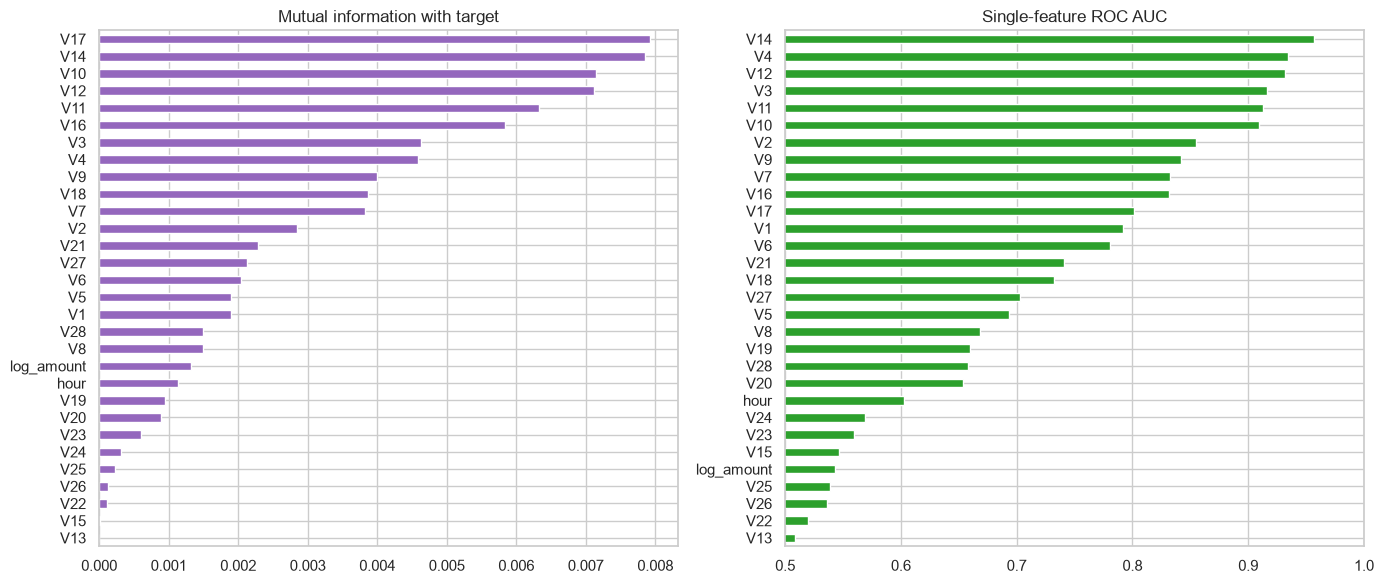

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
importance["mutual_info"].sort_values().plot.barh(ax=axes[0], color="tab:purple")
axes[0].set_title("Mutual information with target")
importance["single_feature_auc"].sort_values().plot.barh(ax=axes[1], color="tab:green")
axes[1].set_xlim(0.5, 1)
axes[1].set_title("Single-feature ROC AUC")
plt.tight_layout()
plt.show()

The ranking is consistent across all three measures. `V14`, `V17`, `V12`,
`V10`, `V11`, `V16`, `V4` and `V3` carry most of the signal, while `V13`,
`V15`, `V22`, `V25` and `V26` carry almost none on their own. The engineered
`hour` and `log_amount` add a little.

All features are kept. Tree models ignore useless features, the linear model
is regularized, and there are only 30 features. The tree-based importance of
the final model is shown in section 6.

## 4. Model training and tuning

Three model families, each tuned on the validation set (PR-AUC):

| Model | Why | Tuned parameters |
|---|---|---|
| Logistic regression | Linear baseline, fast, interpretable | `C`, `class_weight` |
| Random forest | Bagged trees, captures non-linearity | `max_depth`, `min_samples_leaf`, `class_weight` |
| XGBoost | Gradient boosting, usually strongest on tabular data | `max_depth`, `learning_rate`, `min_child_weight`, `scale_pos_weight`, number of trees (early stopping) |

Class imbalance is handled with class weights (`class_weight` /
`scale_pos_weight`) as a tunable option rather than by resampling, so the model
sees all the real data.

In [16]:
def evaluate(y_true, y_pred):
    return {
        "pr_auc": average_precision_score(y_true, y_pred),
        "roc_auc": roc_auc_score(y_true, y_pred),
    }

def none_if_nan(value):
    # grid results live in DataFrames, where None turns into NaN - convert back
    return None if pd.isna(value) else value


results = {}

### 4.1 Logistic regression

In [17]:
rows = []
for class_weight in [None, "balanced"]:
    for C in [0.001, 0.01, 0.1, 1, 10]:
        model = make_pipeline(
            StandardScaler(),
            LogisticRegression(C=C, class_weight=class_weight, max_iter=5000),
        )
        model.fit(X_train, y_train)
        y_pred = model.predict_proba(X_val)[:, 1]
        rows.append({"C": C, "class_weight": class_weight, **evaluate(y_val, y_pred)})

lr_scores = pd.DataFrame(rows).sort_values("pr_auc", ascending=False)
lr_scores.round(4)

,C,class_weight,pr_auc,roc_auc
1,0.010,NaN,0.7987,0.9804
2,0.100,NaN,0.7978,0.9785
3,1.000,NaN,0.7967,0.9774
4,10.000,NaN,0.7967,0.9773
6,0.010,balanced,0.7921,0.9819
7,0.100,balanced,0.7901,0.9826
8,1.000,balanced,0.7900,0.9826
9,10.000,balanced,0.7892,0.9827
5,0.001,balanced,0.7879,0.9802
0,0.001,NaN,0.7873,0.9814


Best logistic regression: {'C': 0.01, 'class_weight': None}


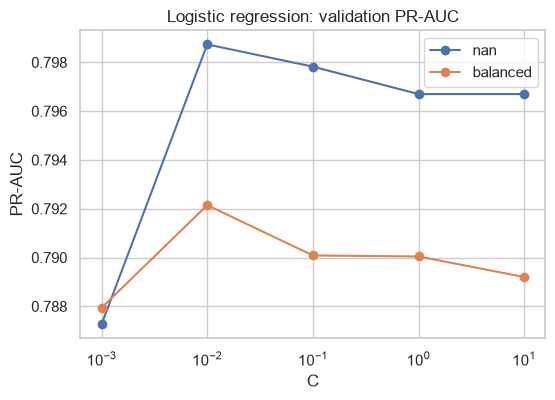

In [18]:
best_lr = lr_scores.iloc[0]
lr_params = {"C": float(best_lr["C"]), "class_weight": none_if_nan(best_lr["class_weight"])}
results["logistic_regression"] = best_lr[["pr_auc", "roc_auc"]].to_dict()
print("Best logistic regression:", lr_params)

pivot = lr_scores.pivot(index="C", columns="class_weight", values="pr_auc")
pivot.columns = [str(c) for c in pivot.columns]
pivot.plot(marker="o", logx=True, figsize=(6, 4), title="Logistic regression: validation PR-AUC")
plt.ylabel("PR-AUC")
plt.show()

`class_weight="balanced"` raises ROC AUC but **lowers** PR-AUC. Up-weighting
fraud pushes many legitimate transactions to higher scores, which makes the
alerts noisier.

### 4.2 Random forest

In [19]:
rows = []
for class_weight in [None, "balanced_subsample"]:
    for max_depth in [10, 20, None]:
        for min_samples_leaf in [1, 5]:
            model = RandomForestClassifier(
                n_estimators=100,
                max_depth=max_depth,
                min_samples_leaf=min_samples_leaf,
                class_weight=class_weight,
                n_jobs=-1,
                random_state=SEED,
            )
            model.fit(X_train, y_train)
            y_pred = model.predict_proba(X_val)[:, 1]
            rows.append({
                "class_weight": class_weight,
                "max_depth": max_depth,
                "min_samples_leaf": min_samples_leaf,
                **evaluate(y_val, y_pred),
            })

rf_scores = pd.DataFrame(rows).sort_values("pr_auc", ascending=False)
rf_scores.round(4)

,class_weight,max_depth,min_samples_leaf,pr_auc,roc_auc
2,NaN,20.0,1,0.8764,0.9591
4,NaN,NaN,1,0.8749,0.9509
8,balanced_subsample,20.0,1,0.8740,0.9611
10,balanced_subsample,NaN,1,0.8733,0.9458
3,NaN,20.0,5,0.8733,0.9668
0,NaN,10.0,1,0.8732,0.9708
5,NaN,NaN,5,0.8724,0.9485
1,NaN,10.0,5,0.8708,0.9660
9,balanced_subsample,20.0,5,0.8688,0.9648
11,balanced_subsample,NaN,5,0.8679,0.9598


In [20]:
best_rf = rf_scores.iloc[0]
rf_params = {
    "class_weight": none_if_nan(best_rf["class_weight"]),
    "max_depth": None if pd.isna(best_rf["max_depth"]) else int(best_rf["max_depth"]),
    "min_samples_leaf": int(best_rf["min_samples_leaf"]),
}
print("Best random forest:", rf_params)

Best random forest: {'class_weight': None, 'max_depth': 20, 'min_samples_leaf': 1}


Number of trees, with the best settings above:

,n_estimators,pr_auc,roc_auc
0,50,0.8700,0.9588
1,100,0.8764,0.9591
2,200,0.8773,0.9665
3,300,0.8764,0.9685


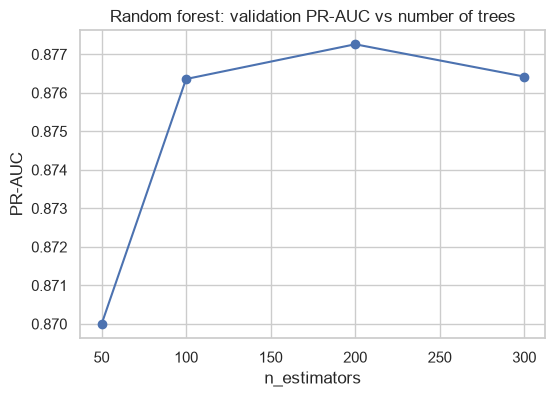

Best random forest: {'class_weight': None, 'max_depth': 20, 'min_samples_leaf': 1, 'n_estimators': 200}


In [21]:
rows = []
for n_estimators in [50, 100, 200, 300]:
    model = RandomForestClassifier(n_estimators=n_estimators, n_jobs=-1, random_state=SEED, **rf_params)
    model.fit(X_train, y_train)
    rows.append({"n_estimators": n_estimators, **evaluate(y_val, model.predict_proba(X_val)[:, 1])})

rf_trees = pd.DataFrame(rows)
display(rf_trees.round(4))
rf_trees.plot(x="n_estimators", y="pr_auc", marker="o", figsize=(6, 4),
              title="Random forest: validation PR-AUC vs number of trees", legend=False)
plt.ylabel("PR-AUC")
plt.show()

rf_params["n_estimators"] = int(rf_trees.sort_values("pr_auc", ascending=False).iloc[0]["n_estimators"])
results["random_forest"] = rf_trees.sort_values("pr_auc", ascending=False).iloc[0][["pr_auc", "roc_auc"]].to_dict()
print("Best random forest:", rf_params)

### 4.3 XGBoost

The number of trees is found with early stopping on the validation PR-AUC
(`aucpr`). Up to 2000 trees are allowed, and training stops after 100 rounds
without improvement.

In [22]:
neg_pos_ratio = (y_train == 0).sum() / (y_train == 1).sum()
print(f"negative/positive ratio: {neg_pos_ratio:.0f}")

rows = []
for max_depth in [3, 4, 6, 8]:
    for learning_rate in [0.05, 0.1]:
        for min_child_weight in [1, 5]:
            for scale_pos_weight in [1, 10]:
                model = xgb.XGBClassifier(
                    n_estimators=2000,
                    max_depth=max_depth,
                    learning_rate=learning_rate,
                    min_child_weight=min_child_weight,
                    scale_pos_weight=scale_pos_weight,
                    eval_metric="aucpr",
                    early_stopping_rounds=100,
                    n_jobs=-1,
                    random_state=SEED,
                )
                model.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)
                y_pred = model.predict_proba(X_val)[:, 1]
                rows.append({
                    "max_depth": max_depth,
                    "learning_rate": learning_rate,
                    "min_child_weight": min_child_weight,
                    "scale_pos_weight": scale_pos_weight,
                    "n_estimators": model.best_iteration + 1,
                    **evaluate(y_val, y_pred),
                })

xgb_scores = pd.DataFrame(rows).sort_values("pr_auc", ascending=False)
xgb_scores.head(10).round(4)

negative/positive ratio: 598


,max_depth,learning_rate,min_child_weight,scale_pos_weight,n_estimators,pr_auc,roc_auc
25,8,0.05,1,10,165,0.8931,0.9786
31,8,0.10,5,10,194,0.8926,0.9792
13,4,0.10,1,10,324,0.8926,0.9773
29,8,0.10,1,10,79,0.8925,0.9801
11,4,0.05,5,10,395,0.8920,0.9765
9,4,0.05,1,10,363,0.8919,0.9774
27,8,0.05,5,10,163,0.8908,0.9743
17,6,0.05,1,10,258,0.8904,0.9842
21,6,0.10,1,10,94,0.8902,0.9813
15,4,0.10,5,10,373,0.8900,0.9754


Best XGBoost: {'max_depth': 8, 'learning_rate': 0.05, 'min_child_weight': 1, 'scale_pos_weight': 10.0, 'n_estimators': 165}


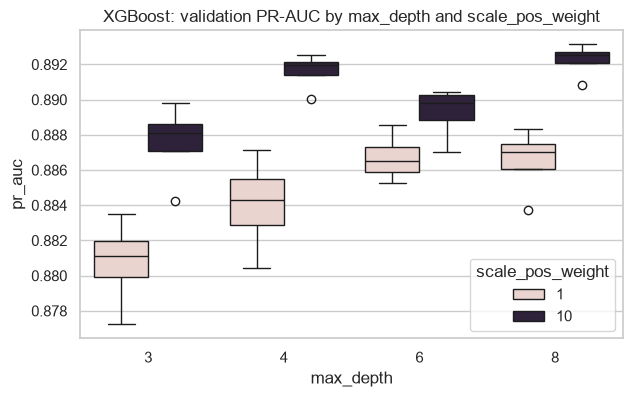

In [23]:
best_xgb = xgb_scores.iloc[0]
xgb_params = {
    "max_depth": int(best_xgb["max_depth"]),
    "learning_rate": float(best_xgb["learning_rate"]),
    "min_child_weight": int(best_xgb["min_child_weight"]),
    "scale_pos_weight": float(best_xgb["scale_pos_weight"]),
    "n_estimators": int(best_xgb["n_estimators"]),
}
results["xgboost"] = best_xgb[["pr_auc", "roc_auc"]].to_dict()
print("Best XGBoost:", xgb_params)

fig, ax = plt.subplots(figsize=(7, 4))
sns.boxplot(data=xgb_scores, x="max_depth", y="pr_auc", hue="scale_pos_weight", ax=ax)
ax.set_title("XGBoost: validation PR-AUC by max_depth and scale_pos_weight")
plt.show()

### 4.4 Validation summary

In [24]:
pd.DataFrame(results).T.sort_values("pr_auc", ascending=False).round(4)

,pr_auc,roc_auc
xgboost,0.8931,0.9786
random_forest,0.8773,0.9665
logistic_regression,0.7987,0.9804


Note: XGBoost's score is slightly optimistic, because the validation set was
also used for early stopping. With only ~95 frauds in the validation set, the
differences between models are also noisy. Both issues are addressed by the
cross-validation in the next section.

## 5. Model selection with cross-validation

The three tuned models are compared with **5-fold stratified cross-validation**
on train + validation combined (~227k rows, ~380 frauds). Each model is scored
on ~5x more fraud cases than with the single validation set, and XGBoost uses a
fixed number of trees (no early stopping on the evaluation fold).

In [25]:
df_full_train = pd.concat([df_train, df_val], ignore_index=True)
X_full, y_full = add_features(df_full_train), df_full_train[TARGET].values


def make_model(name):
    if name == "logistic_regression":
        return make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000, **lr_params))
    if name == "random_forest":
        return RandomForestClassifier(n_jobs=-1, random_state=SEED, **rf_params)
    if name == "xgboost":
        return xgb.XGBClassifier(n_jobs=-1, random_state=SEED, **xgb_params)
    raise ValueError(name)


kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_rows = []
oof = {}  # out-of-fold predictions, used for the threshold later
for name in ["logistic_regression", "random_forest", "xgboost"]:
    oof[name] = np.zeros(len(y_full))
    for fold, (tr_idx, va_idx) in enumerate(kfold.split(X_full, y_full)):
        model = make_model(name)
        model.fit(X_full.iloc[tr_idx], y_full[tr_idx])
        y_pred = model.predict_proba(X_full.iloc[va_idx])[:, 1]
        oof[name][va_idx] = y_pred
        cv_rows.append({"model": name, "fold": fold, **evaluate(y_full[va_idx], y_pred)})

cv_scores = pd.DataFrame(cv_rows)
cv_summary = cv_scores.groupby("model")[["pr_auc", "roc_auc"]].agg(["mean", "std"]).sort_values(
    ("pr_auc", "mean"), ascending=False
)
cv_summary.round(4)

pr_auc         roc_auc        
                       mean     std    mean     std
model                                              
xgboost              0.8517  0.0254  0.9814  0.0076
random_forest        0.8498  0.0257  0.9743  0.0141
logistic_regression  0.7592  0.0402  0.9843  0.0067

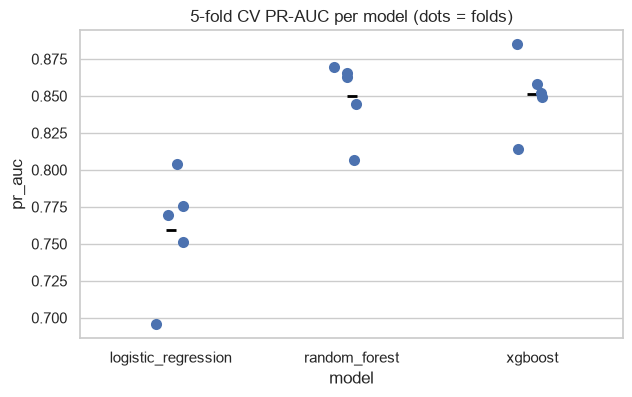

Selected model: xgboost


In [26]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.stripplot(data=cv_scores, x="model", y="pr_auc", size=8, ax=ax)
sns.pointplot(data=cv_scores, x="model", y="pr_auc", color="black", markers="_",
              linestyles="none", errorbar=None, ax=ax)
ax.set_title("5-fold CV PR-AUC per model (dots = folds)")
plt.show()

best_name = cv_summary.index[0]
print("Selected model:", best_name)

Results:

- **XGBoost and random forest are statistically tied.** Their mean PR-AUC
  differs by ~0.002, far less than the fold-to-fold standard deviation
  (~0.025). Logistic regression is clearly worse on PR-AUC (~0.76), even
  though its ROC AUC is the highest. That is a good illustration of why ROC
  AUC is misleading on such imbalanced data.
- **XGBoost is selected.** It has the highest mean PR-AUC, and among the two
  tied models it is the practical choice for a real-time service: it trains
  roughly 8x faster and produces a much smaller model file than a 200-tree,
  depth-20 random forest.

Its hyperparameters are what `train.py` uses.

## 6. Decision threshold and final evaluation

The service returns a probability **and** a yes/no `is_fraud` flag. The flag
needs a threshold, and 0.5 is arbitrary. The threshold is chosen on the
**out-of-fold predictions** from cross-validation (so the test set is not
touched): the one that maximizes F1, i.e. balances catching fraud (recall)
against the share of alerts that are real fraud (precision).

In production, the bank would pick this point from its own costs: the loss per
missed fraud vs the cost of reviewing or annoying a legitimate customer.

threshold = 0.703  precision = 0.929  recall = 0.802  F1 = 0.861


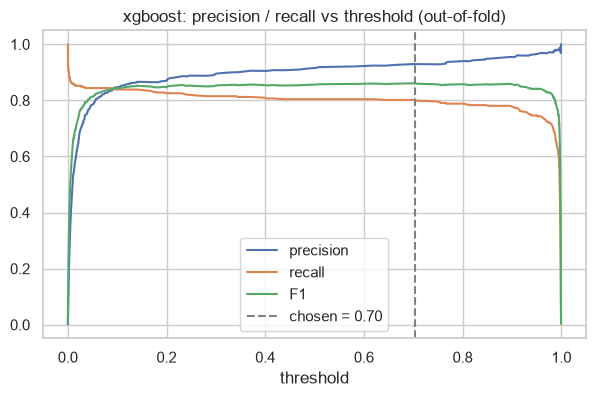

In [27]:
precision, recall, thresholds = precision_recall_curve(y_full, oof[best_name])
f1 = 2 * precision * recall / (precision + recall + 1e-12)
best_idx = int(np.argmax(f1[:-1]))
threshold = float(thresholds[best_idx])
print(f"threshold = {threshold:.3f}  precision = {precision[best_idx]:.3f}  "
      f"recall = {recall[best_idx]:.3f}  F1 = {f1[best_idx]:.3f}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(thresholds, precision[:-1], label="precision")
ax.plot(thresholds, recall[:-1], label="recall")
ax.plot(thresholds, f1[:-1], label="F1")
ax.axvline(threshold, color="grey", linestyle="--", label=f"chosen = {threshold:.2f}")
ax.set_xlabel("threshold")
ax.set_title(f"{best_name}: precision / recall vs threshold (out-of-fold)")
ax.legend()
plt.show()

### Final model on the test set

The selected model is retrained on train + validation and evaluated **once** on
the held-out test set. `train.py` does exactly the same.

Test PR-AUC:  0.8067
Test ROC AUC: 0.9754
At threshold 0.703: precision = 0.946, recall = 0.737


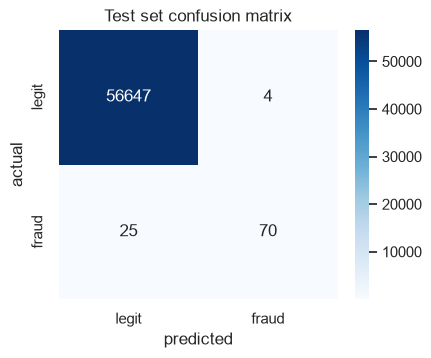

In [28]:
final_model = make_model(best_name)
final_model.fit(X_full, y_full)
y_test_pred = final_model.predict_proba(X_test)[:, 1]
test_metrics = evaluate(y_test, y_test_pred)
y_test_flag = (y_test_pred >= threshold).astype(int)

print(f"Test PR-AUC:  {test_metrics['pr_auc']:.4f}")
print(f"Test ROC AUC: {test_metrics['roc_auc']:.4f}")
print(f"At threshold {threshold:.3f}: precision = {precision_score(y_test, y_test_flag):.3f}, "
      f"recall = {recall_score(y_test, y_test_flag):.3f}")

cm = confusion_matrix(y_test, y_test_flag)
plt.figure(figsize=(4.5, 3.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["legit", "fraud"], yticklabels=["legit", "fraud"])
plt.xlabel("predicted")
plt.ylabel("actual")
plt.title("Test set confusion matrix")
plt.show()

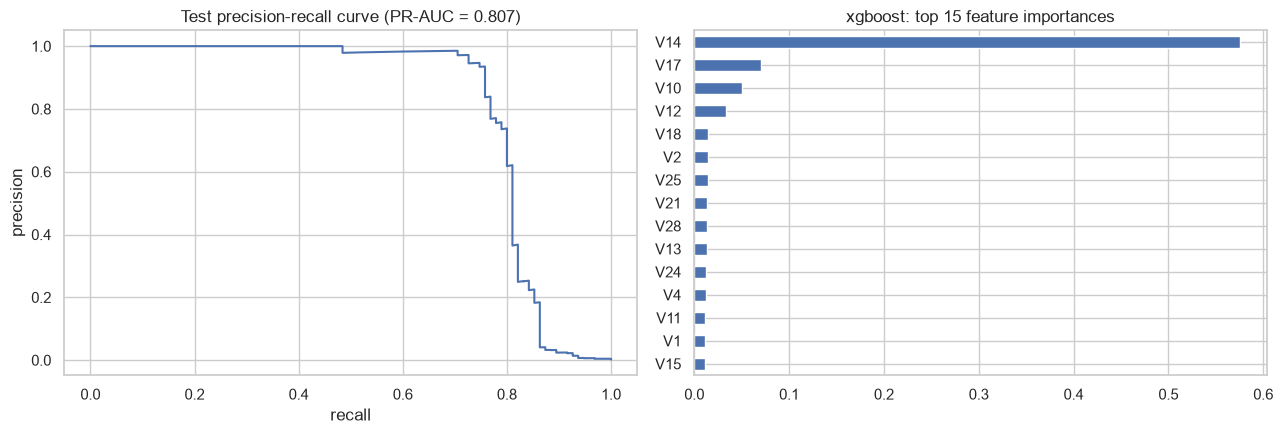

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
p, r, _ = precision_recall_curve(y_test, y_test_pred)
axes[0].plot(r, p)
axes[0].set_xlabel("recall")
axes[0].set_ylabel("precision")
axes[0].set_title(f"Test precision-recall curve (PR-AUC = {test_metrics['pr_auc']:.3f})")

if hasattr(final_model, "feature_importances_"):
    pd.Series(final_model.feature_importances_, index=FEATURES).sort_values().tail(15).plot.barh(ax=axes[1])
    axes[1].set_title(f"{best_name}: top 15 feature importances")
plt.tight_layout()
plt.show()

## Summary

- **Data:** 284,807 transactions. 1,081 exact duplicates were removed, leaving
  283,726 rows with 473 frauds (0.167%). `Amount` is log-transformed and `Time`
  is turned into hour of day.
- **EDA:** a handful of PCA components (`V14`, `V17`, `V12`, `V10`, `V3`, ...)
  carry most of the signal. Fraud is far more frequent at night (~1-1.5% of
  transactions at 2-4 am vs ~0.1% during the day).
- **Models** (5-fold CV PR-AUC): XGBoost 0.852 ≈ random forest 0.850 >
  logistic regression 0.759. XGBoost is selected.
- **Test set** (held out until the end): PR-AUC 0.807, ROC AUC 0.975. At the
  F1-optimal threshold of 0.70, **95% of fraud alerts are real fraud
  (precision) and 74% of frauds are caught (recall)**. The test PR-AUC is below
  the CV mean but within its spread. With only 95 test frauds, a few hard cases
  move the score noticeably.
- The final model, its parameters and the threshold are reproduced in
  `train.py`, which saves the model to `models/model.bin` for `predict.py`.

In [30]:
print("Model:", best_name)
print("Params:", {"logistic_regression": lr_params, "random_forest": rf_params, "xgboost": xgb_params}[best_name])
print("Threshold:", round(threshold, 4))

Model: xgboost
Params: {'max_depth': 8, 'learning_rate': 0.05, 'min_child_weight': 1, 'scale_pos_weight': 10.0, 'n_estimators': 165}
Threshold: 0.7029
